In [1]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import librosa

from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV

from IPython.display import Audio, display
import soundfile as sf
print(sf.__libsndfile_version__)

import warnings
warnings.filterwarnings("ignore", message="n_fft=.*too large for input signal")

1.2.2


In [2]:
DATA_DIR = Path("data/audio")

CLEAN_DIR = DATA_DIR / "clean"
DIRTY_DIR = DATA_DIR / "dirty"

SAMPLERATE = 22050

In [3]:
audio_extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}

#This gathers every clean file
cleanFiles = [
    path for path in CLEAN_DIR.rglob("*")
    if path.suffix.lower() in audio_extensions
]

print(f"Number of clean recordings: {len(cleanFiles)}")

Number of clean recordings: 478


In [4]:
def labels(fileList):
    records= []

    for filePath in fileList:
        fileName = filePath.name
        stem = filePath.stem
        chordName = re.sub(r"\d+$", "", stem)
        records.append({
            "filename": fileName,
            "filepath" : str(filePath),
            "chord" : chordName,
        })

    return records


In [5]:
def extractFeatures(path):
    y, sr = librosa.load(path, sr=SAMPLERATE,  mono = True)
    y, _ = librosa.effects.trim(y)

    feats = {}

    #Most useful feature
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr)
    for i in range(12):
        feats[f"chroma_mean_{i}"] = chroma[i].mean()
        feats[f"chroma_std_{i}"] = chroma[i].std()

    timbre = librosa.feature.mfcc(y=y, sr=sr)
    for i in range(13):
        feats[f"timbre_mean_{i}"] = timbre[i].mean()
        feats[f"timbre_std_{i}"] = timbre[i].std()


    feats["spec_centroid"] = librosa.feature.spectral_centroid(y=y, sr=sr).mean()
    feats["spec_bandwidth"] = librosa.feature.spectral_bandwidth(y=y, sr=sr).mean()
    feats["spec_rolloff"] = librosa.feature.spectral_rolloff(y=y, sr=sr).mean()
    feats["zcr"] = librosa.feature.zero_crossing_rate(y).mean()
    feats["rms"] = librosa.feature.rms(y=y).mean()
    return feats

In [6]:
records = labels(cleanFiles)

for r in records:
    r.update(extractFeatures(r["filepath"]))

df = pd.DataFrame(records)


In [7]:
df.head(5)

X = df.drop(columns=["filename", "filepath", "chord"])
y = df["chord"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state=0,
    stratify=y)


In [8]:
logRegModel = Pipeline([('scaler', StandardScaler()),
           ('logreg', LogisticRegression(solver='saga', max_iter=10000))])

paramGrid = {
    'logreg__C': np.logspace(-3,2,20),
    'logreg__l1_ratio': [0, 0.5, 1]}

cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=0)
grid = GridSearchCV(logRegModel, paramGrid, cv=cv, scoring='accuracy', refit=True)
    

In [9]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logreg__C': array([1.0000...00000000e+02]), 'logreg__l1_ratio': [0, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verb

In [10]:
print(grid.best_params_)
final_model = grid.best_estimator_

{'logreg__C': np.float64(2.636650898730358), 'logreg__l1_ratio': 1}



TRAINING SET
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        43
          Am       1.00      1.00      1.00        45
           C       1.00      1.00      1.00        48
           D       1.00      1.00      1.00        51
          Dm       1.00      1.00      1.00        53
           E       1.00      1.00      1.00        48
          Em       1.00      1.00      1.00        46
           G       1.00      1.00      1.00        48

    accuracy                           1.00       382
   macro avg       1.00      1.00      1.00       382
weighted avg       1.00      1.00      1.00       382



TEST SET
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        11
          Am       1.00      1.00      1.00        11
           C       1.00      1.00      1.00        12
           D       1.00      0.92      0.96        13
          Dm       0.93      1.00      0.96        13

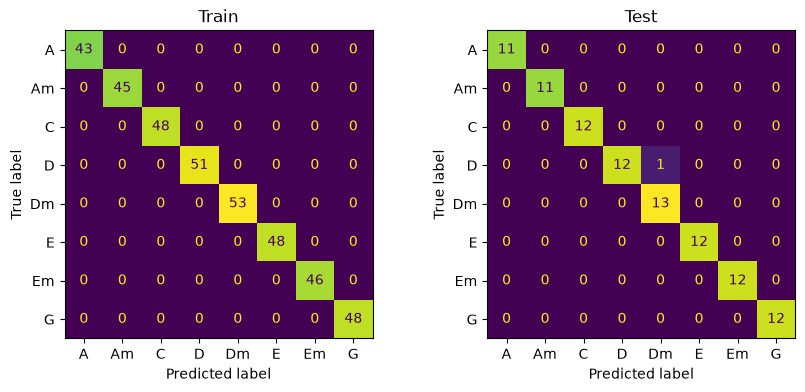

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(final_model, X_train, y_train, ax=axes[0], colorbar=False)
axes[0].set_title('Train')
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, ax=axes[1], colorbar=False)
axes[1].set_title('Test')

print(f"\nTRAINING SET")
print(classification_report(y_train, final_model.predict(X_train)))

print(f"\n\nTEST SET")
print(classification_report(y_test, final_model.predict(X_test)))


===== Test1 (n=5) =====
INCORRECT FILES 

Empty DataFrame
Columns: [filename, chord, pred]
Index: []


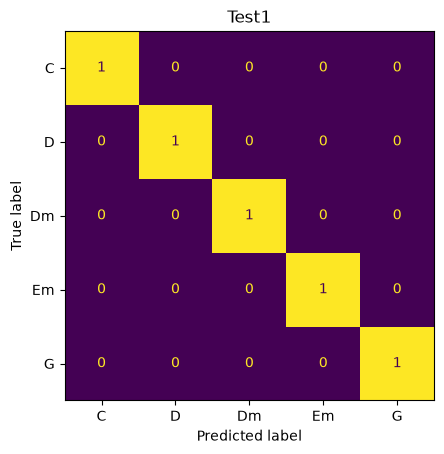

              precision    recall  f1-score   support

           C       1.00      1.00      1.00         1
           D       1.00      1.00      1.00         1
          Dm       1.00      1.00      1.00         1
          Em       1.00      1.00      1.00         1
           G       1.00      1.00      1.00         1

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


===== Test2 (n=5) =====
INCORRECT FILES 

Empty DataFrame
Columns: [filename, chord, pred]
Index: []


C:\Users\danny\anaconda3\envs\chords\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


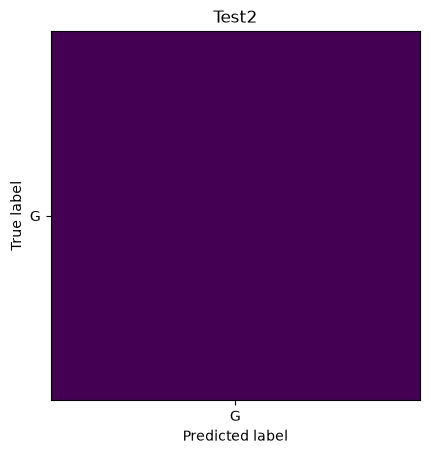

              precision    recall  f1-score   support

           G       1.00      1.00      1.00         5

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


===== Test3 (n=1) =====
INCORRECT FILES 

Empty DataFrame
Columns: [filename, chord, pred]
Index: []


C:\Users\danny\anaconda3\envs\chords\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


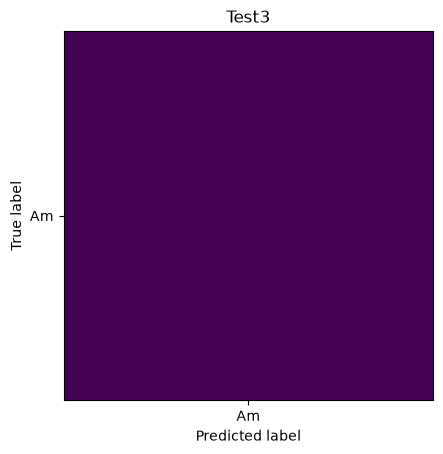

              precision    recall  f1-score   support

          Am       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1


===== Test4 (n=4) =====
INCORRECT FILES 

  filename chord pred
0   D1.wav     D   Am
1   D2.wav     D   Dm


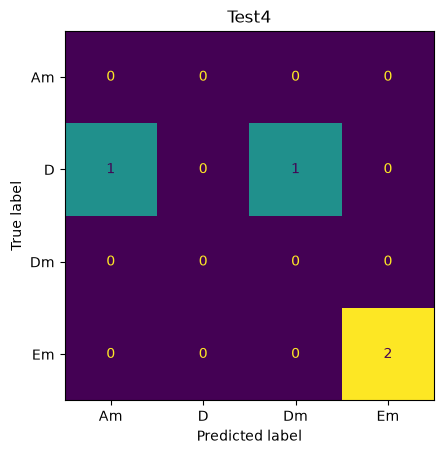

              precision    recall  f1-score   support

          Am       0.00      0.00      0.00         0
           D       0.00      0.00      0.00         2
          Dm       0.00      0.00      0.00         0
          Em       1.00      1.00      1.00         2

    accuracy                           0.50         4
   macro avg       0.25      0.25      0.25         4
weighted avg       0.50      0.50      0.50         4


===== Test5 (n=9) =====
INCORRECT FILES 

   filename chord pred
0  Am10.wav    Am    C
1  Am11.wav    Am    C
2  Am13.wav    Am    C


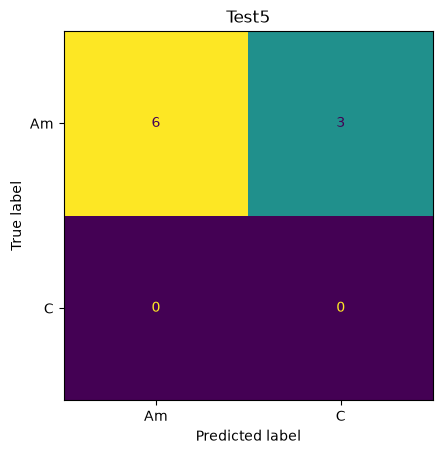

              precision    recall  f1-score   support

          Am       1.00      0.67      0.80         9
           C       0.00      0.00      0.00         0

    accuracy                           0.67         9
   macro avg       0.50      0.33      0.40         9
weighted avg       1.00      0.67      0.80         9



In [31]:
'''
This is tested against items purposefully excluded from the training or test set. These are usually edge Cases.

-Test 1 is entirely arpeggios using a different volume and tone as the training set
-Test 2 is a heavily distorted tone with and without palm muting
-Test 3 is a sample of the song called The Unforgiven, it's an arrpegiated A minor sequence
-Test 4 is a sample of the interlude of Master of Puppets, mistakes were included to see how the model would react
-Test 5 is a listing of many voicings of the Am chord.

'''

holdoutDir = Path("data/audio/Holdout")
holdoutDfs = {}

for testDir in sorted(p for p in holdoutDir.iterdir() if p.is_dir()):

    files = [
        path for path in testDir.rglob("*")
        if path.suffix.lower() in audio_extensions
    ]

    holdoutTest = labels(files)
    for r in holdoutTest:
        r.update(extractFeatures(r["filepath"]))

    dfT = pd.DataFrame(holdoutTest)          
    holdoutDfs[testDir.name] = dfT

    X_t = dfT.drop(columns=["filename", "filepath", "chord"])
    y_t = dfT["chord"]

    print(f"\n===== {testDir.name} (n={len(dfT)}) =====")

    dfT["pred"] = final_model.predict(X_t)
    print("INCORRECT FILES \n")
    print(dfT[["filename", "chord", "pred"]][dfT["chord"] != dfT["pred"]])
    
    ConfusionMatrixDisplay.from_estimator(final_model, X_t, y_t, colorbar=False)
    plt.title(testDir.name)
    plt.show()                        
    print(classification_report(y_t, final_model.predict(X_t), zero_division=0))
    